In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch

plt.style.use("ggplot")

import nltk
#download the punkt tokenizer for sentence splitting
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")
nltk.download('maxent_ne_chunker')
nltk.download('maxent_ne_chunker_tab')
nltk.download('words')
nltk.download('vader_lexicon')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\virjk\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\virjk\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\virjk\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\virjk\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\virjk\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\vir

True

In [3]:
df = pd.read_csv("./Reviews.csv")

In [4]:
df.head()


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [5]:
df["Text"].values[0]

'I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.'

In [6]:
print(df.shape)

(568454, 10)


In [7]:
df = df.head(500)
print(df.shape)
df.head()
#downsize dataset to 500 rows for faster processing

(500, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


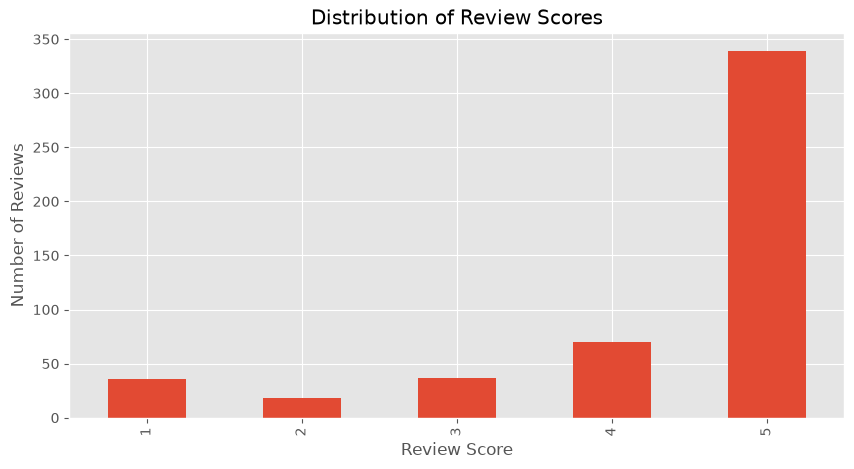

In [8]:
reviewGraph = df["Score"].value_counts().sort_index().plot(kind="bar", title="Distribution of Review Scores", figsize=(10, 5))
reviewGraph.set_xlabel("Review Score")
reviewGraph.set_ylabel("Number of Reviews")
plt.show()
#very biased towards 5 star reviews

In [9]:
#Basic NLTK Preprocessing
exampleText = df["Text"][50]
print(exampleText)
#shows negative sentiment review

This oatmeal is not good. Its mushy, soft, I don't like it. Quaker Oats is the way to go.


In [10]:
tokens = nltk.word_tokenize(exampleText)
#split the review into individual words, splits punctuation as well
tokens[:10]

['This', 'oatmeal', 'is', 'not', 'good', '.', 'Its', 'mushy', ',', 'soft']

In [11]:
tagged = nltk.pos_tag(tokens)
tagged[:10]
#each token and its part of speech, e.g. noun, verb, adjective, etc. Each part of speech is represented by a tag, e.g. NN for noun, VB for verb, JJ for adjective, etc.

[('This', 'DT'),
 ('oatmeal', 'NN'),
 ('is', 'VBZ'),
 ('not', 'RB'),
 ('good', 'JJ'),
 ('.', '.'),
 ('Its', 'PRP$'),
 ('mushy', 'NN'),
 (',', ','),
 ('soft', 'JJ')]

In [12]:
entities = nltk.chunk.ne_chunk(tagged)
entities.pprint()


(S
  This/DT
  oatmeal/NN
  is/VBZ
  not/RB
  good/JJ
  ./.
  Its/PRP$
  mushy/NN
  ,/,
  soft/JJ
  ,/,
  I/PRP
  do/VBP
  n't/RB
  like/VB
  it/PRP
  ./.
  (ORGANIZATION Quaker/NNP Oats/NNPS)
  is/VBZ
  the/DT
  way/NN
  to/TO
  go/VB
  ./.)


In [13]:
#VADER(Valance Aware Dictionary and sEntiment Reasoner) Sentiment Analysis
#Uses "bag of words" approach, where each word is assigned a sentiment score based on its valence (positive or negative) and intensity (strength of the sentiment). The overall sentiment of a text is then calculated by summing the scores of all the words in the text.
#** Does account for relationship between words, e.g. "not good" is negative, even though "good" is positive. It does this by using a set of rules that take into account the context of the words in the text.

from nltk.sentiment import SentimentIntensityAnalyzer
from tqdm import tqdm

sia = SentimentIntensityAnalyzer()


In [14]:
sia.polarity_scores("I love this product!")
#shows positive sentiment score, negative sentiment score, neutral sentiment score, and compound score (overall sentiment score)

{'neg': 0.0, 'neu': 0.308, 'pos': 0.692, 'compound': 0.6696}

In [15]:
sia.polarity_scores("I hate this product!")

{'neg': 0.666, 'neu': 0.334, 'pos': 0.0, 'compound': -0.6114}

In [16]:
sia.polarity_scores(exampleText)
#exampleText is a negative review, so the compound score should be negative

{'neg': 0.22, 'neu': 0.78, 'pos': 0.0, 'compound': -0.5448}

In [17]:
#Run polarity_scores on all reviews
results = {}
for i, row in tqdm(df.iterrows(), total=len(df)):
    text = row["Text"]
    myid = row["Id"]
    results[myid] = sia.polarity_scores(text)



100%|██████████| 500/500 [00:00<00:00, 529.99it/s]


In [18]:
vaders = pd.DataFrame(results).T
vaders = vaders.reset_index().rename(columns={"index": "Id"})
vaders = vaders.merge(df, how="left")

In [19]:
vaders

,Id,neg,neu,pos,compound,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,0.000,0.695,0.305,0.9441,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,0.138,0.862,0.000,-0.5664,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,0.091,0.754,0.155,0.8265,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,0.000,1.000,0.000,0.0000,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,0.000,0.552,0.448,0.9468,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,0.000,0.554,0.446,0.9725,B000G6RYNE,APGAA43E3WPN7,Darren,0,0,5,1201392000,amazing chips,i rarely eat chips but i saw these and tried t...
496,497,0.059,0.799,0.142,0.7833,B000G6RYNE,ABR7HU5H1KNE,Keith,0,0,5,1196726400,Best Chip Ever,This is easily the best potato chip that I hav...
497,498,0.025,0.762,0.212,0.9848,B000G6RYNE,AJQD2WWJYOYFQ,bubbles,0,0,4,1186617600,"Tangy, spicy, and sweet- oh my!",Kettle Chips Spicy Thai potato chips have the ...
498,499,0.041,0.904,0.055,0.1280,B000G6RYNE,A16YH487W9ZYO0,Bruce G. Lindsay,0,0,4,1184198400,An indulgence with a bite,"Okay, I should not eat potato chips, nor shoul..."


In [20]:
vaders.head()
#sentiment scores and metadata for each review, including the original text and the review score

,Id,neg,neu,pos,compound,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,0.000,0.695,0.305,0.9441,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,0.138,0.862,0.000,-0.5664,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,0.091,0.754,0.155,0.8265,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,0.000,1.000,0.000,0.0000,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,0.000,0.552,0.448,0.9468,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


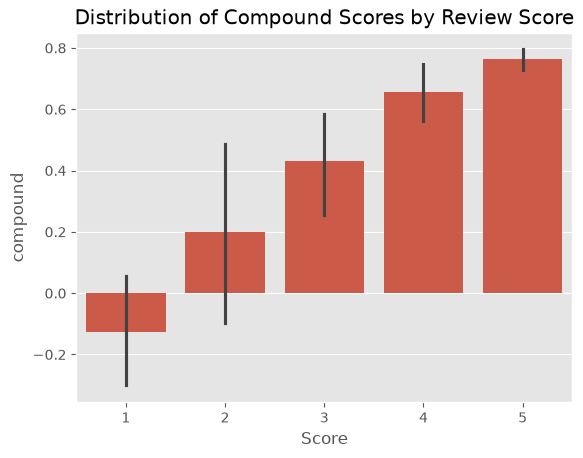

In [21]:
#Plot the distribution of compound scores for each review score from VADER reuslts
vaderGraph = sns.barplot(data = vaders, x = "Score", y = "compound")
vaderGraph.set_title("Distribution of Compound Scores by Review Score")
plt.show()

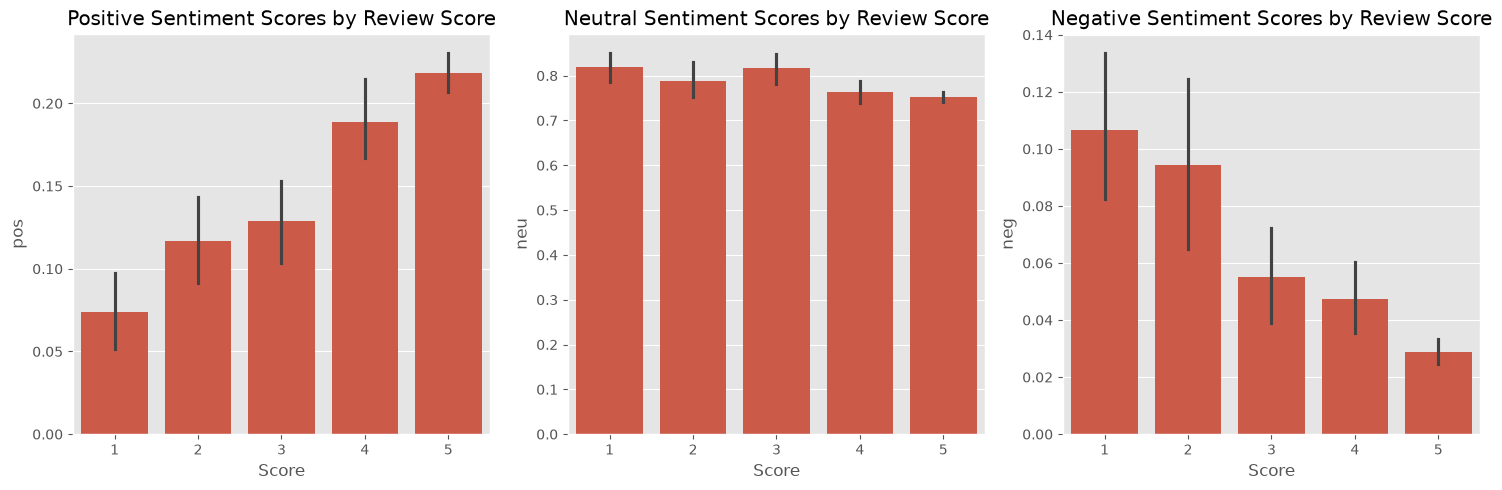

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
sns.barplot(data = vaders, x = "Score", y = "pos", ax=axs[0])
sns.barplot(data = vaders, x = "Score", y = "neu", ax=axs[1])
sns.barplot(data = vaders, x = "Score", y = "neg", ax=axs[2])
axs[0].set_title("Positive Sentiment Scores by Review Score")
axs[1].set_title("Neutral Sentiment Scores by Review Score")
axs[2].set_title("Negative Sentiment Scores by Review Score")
plt.tight_layout()
plt.show()
#all scores have a moderate nuetral sentiment score, with positive and negative scores being lower. This is likely due to the fact that most reviews are positive, so the model is biased towards positive sentiment.

In [23]:
#Hugging Face ROBERT Sentiment Analysis model
#Pretrained on a large corpus of text and fine-tuned on a smaller dataset for sentiment analysis. 
# #It uses a transformer architecture, which allows it to take into account the context of words in a sentence, rather than just looking at individual words in isolation. This allows it to better understand the meaning of a sentence and the sentiment expressed in it.


In [24]:
from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification
from scipy.special import softmax


c:\Users\virjk\OneDrive\Desktop\NLP Sentiment Analysis\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [25]:
MODEL = f"cardiffnlp/twitter-roberta-base-sentiment-latest"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForSequenceClassification.from_pretrained(MODEL)

c:\Users\virjk\OneDrive\Desktop\NLP Sentiment Analysis\myenv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\virjk\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\virjk\OneDrive\Desktop\NLP Sentiment Analysis\myenv\Lib\site-packages\huggingface_hub\file_download.py:149: 

In [ ]:
#VADER results from example
print(exampleText)
sia.polarity_scores(exampleText)

This oatmeal is not good. Its mushy, soft, I don't like it. Quaker Oats is the way to go.


{'neg': 0.22, 'neu': 0.78, 'pos': 0.0, 'compound': -0.5448}

In [ ]:
# Run ROBERTA model Encoding text into embeddings for model
encoded_text = tokenizer(exampleText, return_tensors="pt")
output = model(**encoded_text)
scores = output[0][0].detach().numpy() #convert from tensor to numpy array for easier manipulation
scores = softmax(scores) #convert to probabilities
scores_dict = {
    "roberta_neg": scores[0],
    "roberta_neu": scores[1],
    "roberta_pos": scores[2]
}
print(scores_dict)
#Roberta model identifies exampleText as much more negative than VADER, liely due to the "not good" phrase and the fact that ROBERTA can get relationships between words unlike VADER

{'roberta_neg': np.float32(0.9535124), 'roberta_neu': np.float32(0.040926367), 'roberta_pos': np.float32(0.005561244)}


In [32]:
def polarity_scores_roberta(text):
    encoded_text = tokenizer(text, return_tensors="pt")
    output = model(**encoded_text)
    scores = output[0][0].detach().numpy()
    scores = softmax(scores)
    scores_dict = {
        "roberta_neg": scores[0],
        "roberta_neu": scores[1],
        "roberta_pos": scores[2]
    }
    return scores_dict

In [37]:
#Run polarity_scores on all reviews
results = {}
for i, row in tqdm(df.iterrows(), total=len(df)):
    #SKip large text
    try:
        text = row["Text"]
        myid = row["Id"]
        vader_results = sia.polarity_scores(text)
        vader_results_rename = {}
        for key, value in vader_results.items():
            vader_results_rename[f"vader_{key}"] = value
        roberta_results = polarity_scores_roberta(text)
        both = {**vader_results_rename, **roberta_results}
        results[myid] = both
    except RuntimeError as e:
        print(f"Skipping review {myid} due to error: {e}")
        print(f"Review text: {text} Broke for id {myid}")
        continue



 16%|█▋        | 82/500 [00:34<01:53,  3.69it/s]

Skipping review 83 due to error: index 514 is out of bounds for dimension 1 with size 514
Review text: I know the product title says Molecular Gastronomy, but don't let that scare you off.  I have been looking for this for a while now, not for food science, but for something more down to earth.  I use it to make my own coffee creamer.<br /><br />I have to have my coffee blonde and sweet - but the flavored creamers are full of the bad kinds of fat, and honestly, I hate to use manufactured "food" items.  I really don't think they are good for the body.  On the other hand, I hate using cold milk or cream, because I like HOT coffee.<br /><br />I stumbled across this on Amazon one day and got the idea of making my own creamer.  I also bought low-fat (non-instant) milk powder and regular milk powder. The non-instant lowfat milk is a little sweeter and tastes fresher than regular instant low-fat milk, but does not dissolve good in cold water - which is not a problem for hot coffee.  You will 

 38%|███▊      | 188/500 [01:09<00:58,  5.29it/s]

Skipping review 187 due to error: index 514 is out of bounds for dimension 1 with size 514
Review text: This packet of glaze is the secret to making those European style fresh fruit tarts. I am about to make one for a pie auction at church, after a friend requested that something "strawberry" should be offered. You can make the most amazing and relatively "healthy" fruit tarts by baking a base, layering it with uncooked, fresh, sliced fruit, then pouring over the made-up contents of one of these packets. They harden up at room temperature, hold the fruit together so you can slice the tart, and they let the beauty of the arranged fruit show through. I've also seen this glaze used over cheesecakes, to hold a fruit topping in place. Personally, I do not like cheesecake (too rich for me) but a fruit glazed cheesecake is gorgeous, I will admit. To do this, slice fruit and layer it on the cheesecake while it's still in the springform pan. Pour on the glaze, let it set up and then remove the 

100%|██████████| 500/500 [02:41<00:00,  3.10it/s]


In [38]:
results_df = pd.DataFrame(results).T
results_df = results_df.reset_index().rename(columns={"index": "Id"})
results_df = results_df.merge(df, how="left")

In [39]:
results_df.head()

,Id,vader_neg,vader_neu,vader_pos,vader_compound,roberta_neg,roberta_neu,roberta_pos,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,0.000,0.695,0.305,0.9441,0.010578,0.038816,0.950607,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,0.138,0.862,0.000,-0.5664,0.716768,0.271225,0.012007,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,0.091,0.754,0.155,0.8265,0.005176,0.077858,0.916966,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,0.000,1.000,0.000,0.0000,0.002919,0.047125,0.949957,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,0.000,0.552,0.448,0.9468,0.004527,0.009283,0.986190,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


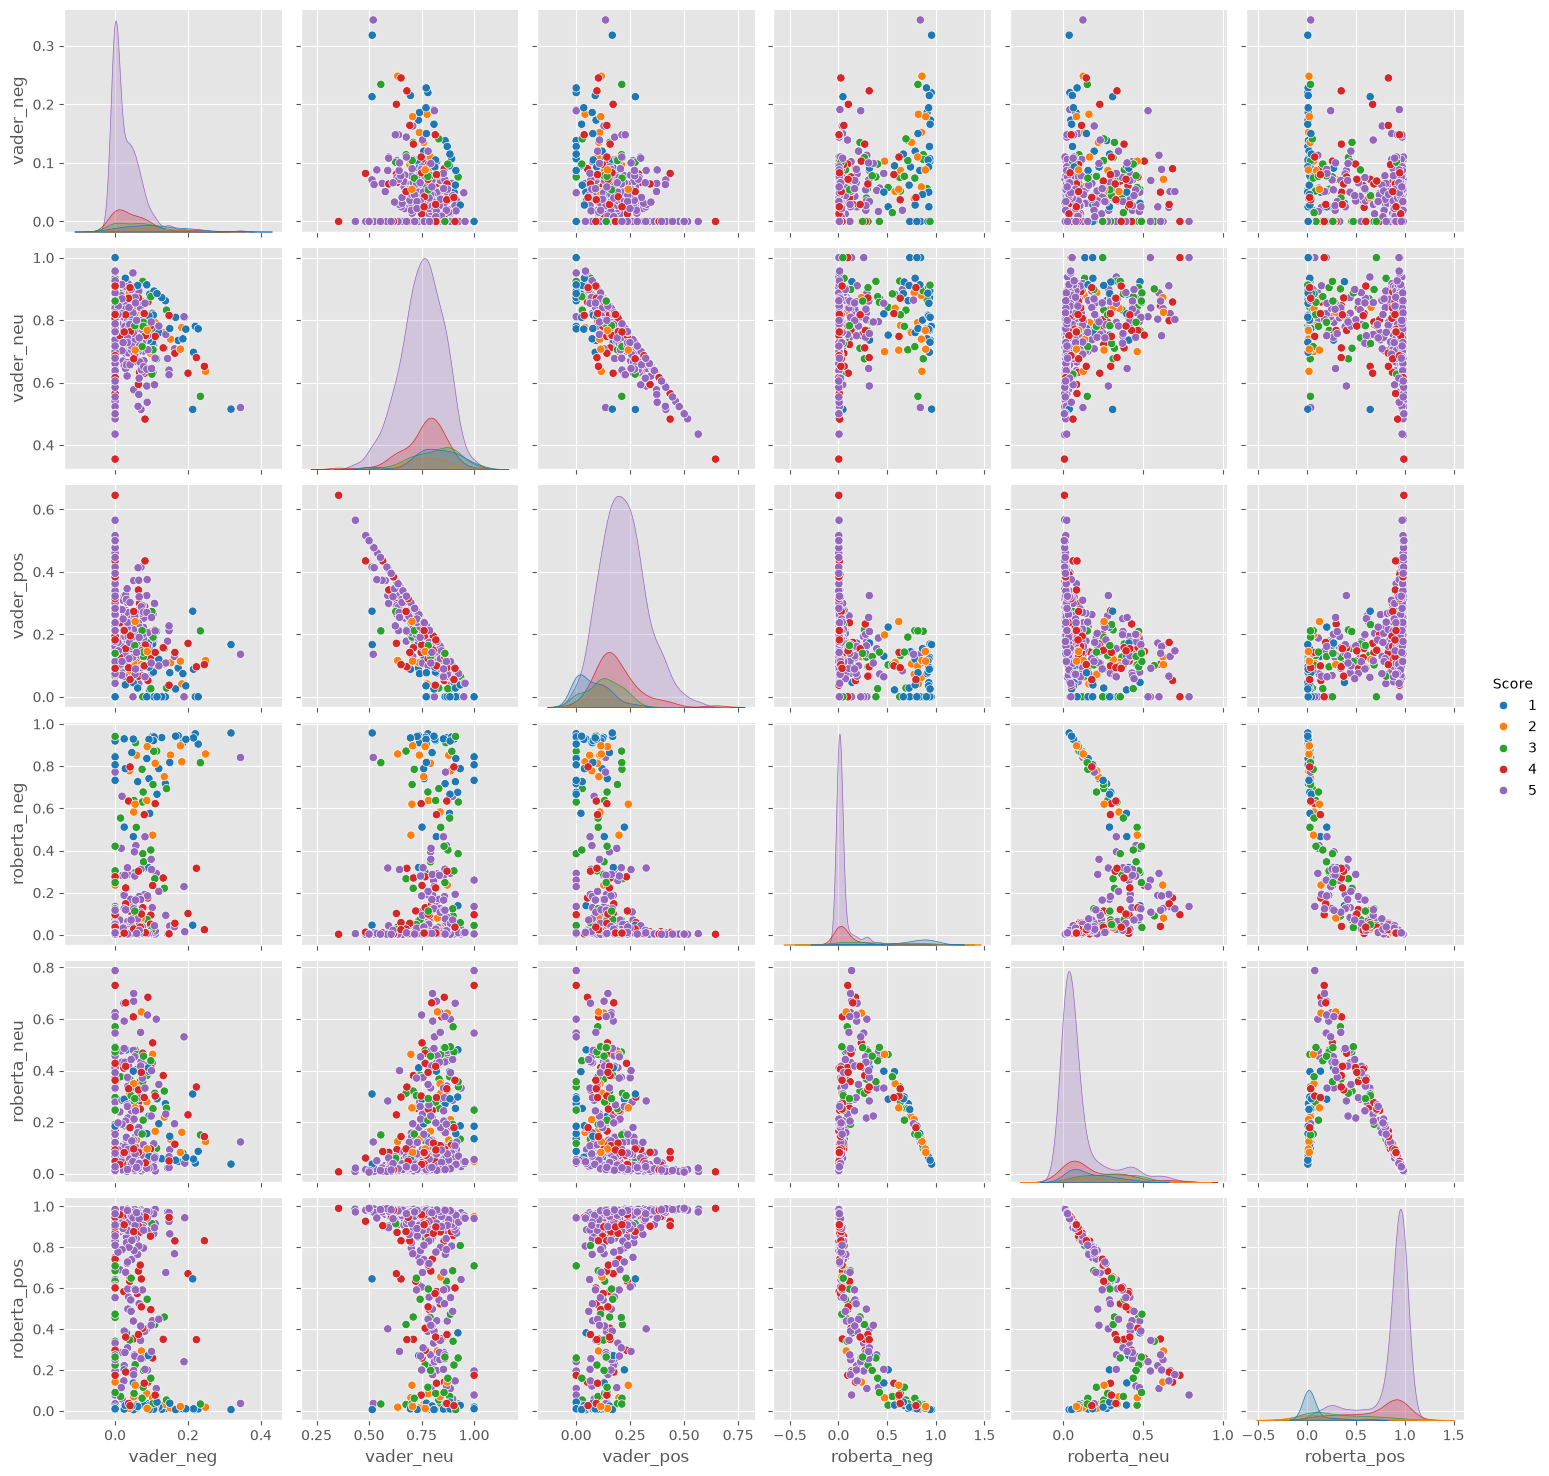

In [ ]:
#Copare scores between modesl
#5 star reviews are purple
#VADER is a lot less confident in scores w/ less correlation
sns.pairplot(results_df, vars=["vader_neg", "vader_neu", "vader_pos", 
                               "roberta_neg", "roberta_neu", "roberta_pos"], 
            hue="Score", palette="tab10")
plt.show()

In [ ]:
#positive sentiment 1 star reviews
results_df.query("Score == 1").sort_values("roberta_pos", ascending=False)["Text"].values[0]
#Model gets confused with these nuancesed/sarcastic scentences

'So we cancelled the order.  It was cancelled without any problem.  That is a positive note...'

In [44]:
results_df.query("Score == 1").sort_values("vader_pos", ascending=False)["Text"].values[0]

'So we cancelled the order.  It was cancelled without any problem.  That is a positive note...'

In [50]:
# negative sentiment 5 star reviews
results_df.query("Score == 5").sort_values("roberta_neg", ascending=False)["Text"].values[0]

'this was sooooo deliscious but too bad i ate em too fast and gained 2 pds! my fault'

In [52]:
results_df.query("Score == 5").sort_values("vader_neg", ascending=False)["Text"].values[0]

'this was sooooo deliscious but too bad i ate em too fast and gained 2 pds! my fault'

In [54]:
#Setup Hugging Face pipeline for sentiment analysis using the ROBERTA model

from transformers import pipeline

sentiment_pipeline = pipeline("sentiment-analysis")

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.
c:\Users\virjk\OneDrive\Desktop\NLP Sentiment Analysis\myenv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\virjk\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administr

In [ ]:

sentiment_pipeline("I love sentiment analysis")

[{'label': 'POSITIVE', 'score': 0.999736487865448}]